# 04 — Analyse exploratoire (EDA) et KPI
### CHU Mohammed VI — Agadir | Module Hospitalisations

**Objectif de ce notebook :**
- Explorer en profondeur les données du Data Warehouse : volumes, démographie, services, séjours, pathologies, médecins, mode de sortie
- Calculer un **tableau de KPI consolidés**, réutilisable directement dans Power BI
- Exporter les résultats dans `data/exports/`

Ce notebook interroge directement le Data Warehouse (`chu_dwh`) construit dans le notebook 03.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text
from dotenv import load_dotenv
import os

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (11, 5)

EXPORT_DIR = "../data/exports"
os.makedirs(EXPORT_DIR, exist_ok=True)

load_dotenv("../.env")
print("Librairies chargées avec succès ")

Librairies chargées avec succès 


## 1. Connexion au Data Warehouse

In [2]:
DB_HOST = os.getenv("DB_HOST", "localhost")
DB_PORT = os.getenv("DB_PORT", "3306")
DB_NAME = os.getenv("DB_NAME", "chu_dwh")
DB_USER = os.getenv("DB_USER", "root")
DB_PASSWORD = os.getenv("DB_PASSWORD")

connection_string = f"mysql+mysqlconnector://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}"
engine = create_engine(connection_string)

with engine.connect() as conn:
    print("Connecté à :", conn.execute(text("SELECT DATABASE();")).fetchone()[0])

Connecté à : chu_dwh


## 2. Chargement du dataframe consolidé

Une seule requête SQL qui joint toutes les dimensions à la table de faits — sert de base à la quasi-totalité des analyses qui suivent (plus rapide que de refaire une requête par graphique).

In [3]:
requete_master = """
SELECT
    f.id_fait,
    f.id_patient,
    p.age,
    p.tranche_age,
    p.sexe,
    p.ville,
    p.groupe_sanguin,
    p.couverture_sante,
    f.id_service,
    s.nom_service,
    s.categorie AS categorie_service,
    s.capacite_lits,
    f.id_medecin,
    m.nom AS nom_medecin,
    m.prenom AS prenom_medecin,
    m.annees_experience,
    t.date_complete AS date_entree,
    t.annee,
    t.mois,
    t.trimestre,
    t.jour_semaine,
    f.duree_sejour,
    f.jours_occupation,
    f.type_admission,
    f.pathologie,
    f.mode_sortie
FROM FactHospitalisation f
JOIN DimPatient p ON f.id_patient = p.id_patient
JOIN DimService s ON f.id_service = s.id_service
JOIN DimTemps t ON f.id_temps = t.id_temps
LEFT JOIN DimMedecin m ON f.id_medecin = m.id_medecin
"""

df = pd.read_sql(requete_master, engine)
print(f"{len(df)} hospitalisations chargées")
df.head()

14580 hospitalisations chargées


,id_fait,id_patient,age,tranche_age,sexe,ville,groupe_sanguin,couverture_sante,id_service,nom_service,...,date_entree,annee,mois,trimestre,jour_semaine,duree_sejour,jours_occupation,type_admission,pathologie,mode_sortie
0,1,7070,5,0-18,M,Sidi Ifni,O+,CNOPS,1,Cardiologie,...,2024-06-26,2024,6,2,Mercredi,10,10,Transfert,Insuffisance cardiaque,Transfert vers un autre service
1,20,4903,7,0-18,M,Ait Melloul,B+,CNSS,1,Cardiologie,...,2026-06-26,2026,6,2,Vendredi,16,16,Programmée,Infarctus du myocarde,Amélioré
2,25,6914,24,19-40,M,Essaouira,A+,CNSS,1,Cardiologie,...,2023-11-02,2023,11,4,Jeudi,14,14,Transfert,Infarctus du myocarde,Guéri
3,33,2641,14,0-18,M,Tanger,O+,CNSS,1,Cardiologie,...,2025-08-06,2025,8,3,Mercredi,9,9,Programmée,Insuffisance cardiaque,Décès
4,46,35,86,60+,F,Chtouka Aït Baha,O+,Sans couverture,1,Cardiologie,...,2025-02-21,2025,2,1,Vendredi,12,12,Programmée,Infarctus du myocarde,Amélioré


## 3. Volumes d'activité

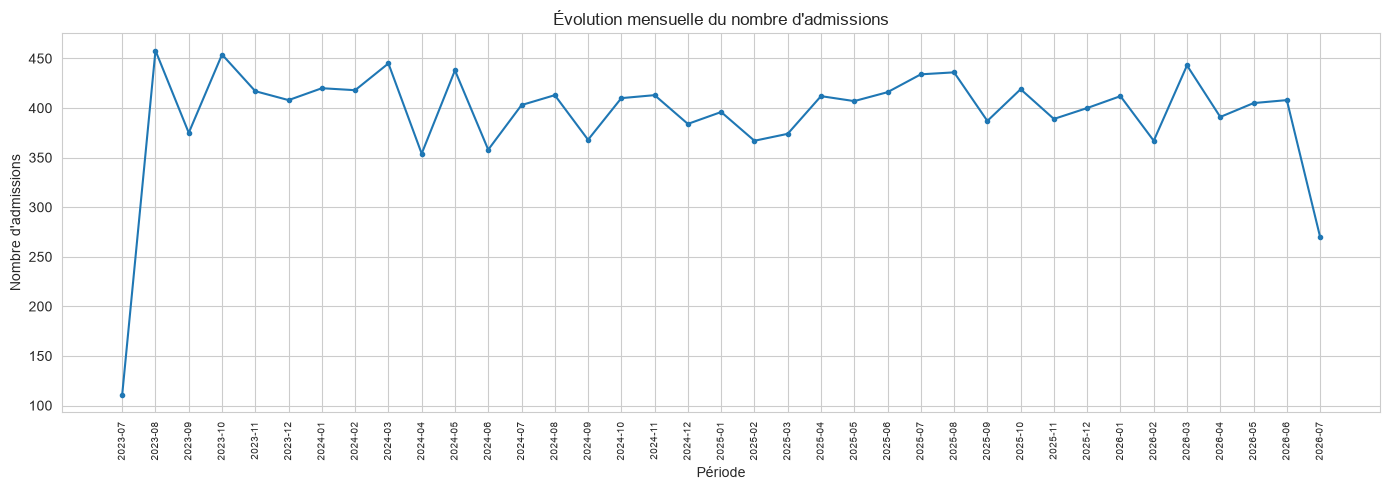

In [4]:
# --- Admissions par mois/année (tendance temporelle) ---
volumes_mensuels = df.groupby(["annee", "mois"]).size().reset_index(name="nb_admissions")
volumes_mensuels["periode"] = volumes_mensuels["annee"].astype(str) + "-" + volumes_mensuels["mois"].astype(str).str.zfill(2)

plt.figure(figsize=(14, 5))
plt.plot(volumes_mensuels["periode"], volumes_mensuels["nb_admissions"], marker="o", markersize=3)
plt.xticks(rotation=90, fontsize=7)
plt.title("Évolution mensuelle du nombre d'admissions")
plt.xlabel("Période")
plt.ylabel("Nombre d'admissions")
plt.tight_layout()
plt.show()

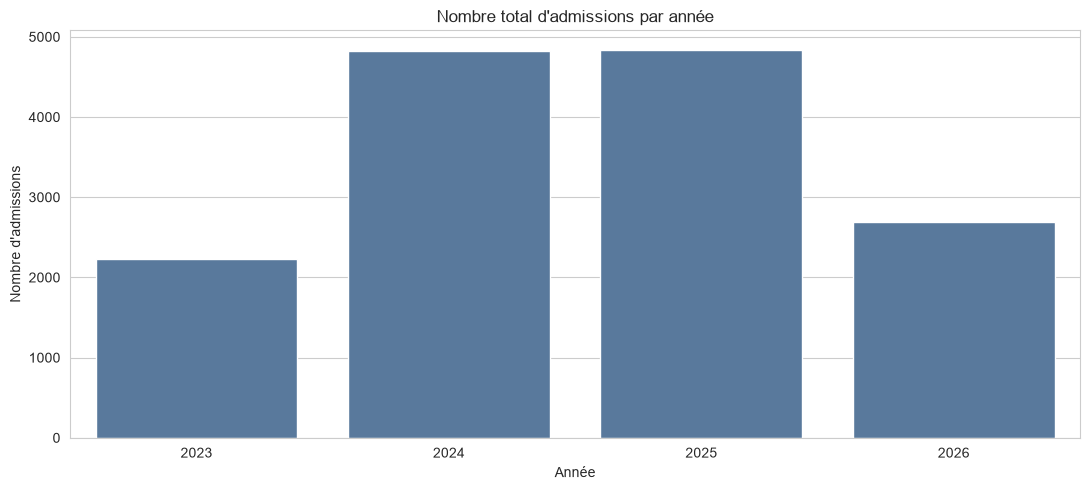

,annee,nb_admissions
0,2023,2223
1,2024,4824
2,2025,4837
3,2026,2696


In [5]:
# --- Admissions par année ---
volumes_annuels = df.groupby("annee").size().reset_index(name="nb_admissions")

plt.figure()
sns.barplot(data=volumes_annuels, x="annee", y="nb_admissions", color="#4E79A7")
plt.title("Nombre total d'admissions par année")
plt.xlabel("Année")
plt.ylabel("Nombre d'admissions")
plt.tight_layout()
plt.show()

volumes_annuels

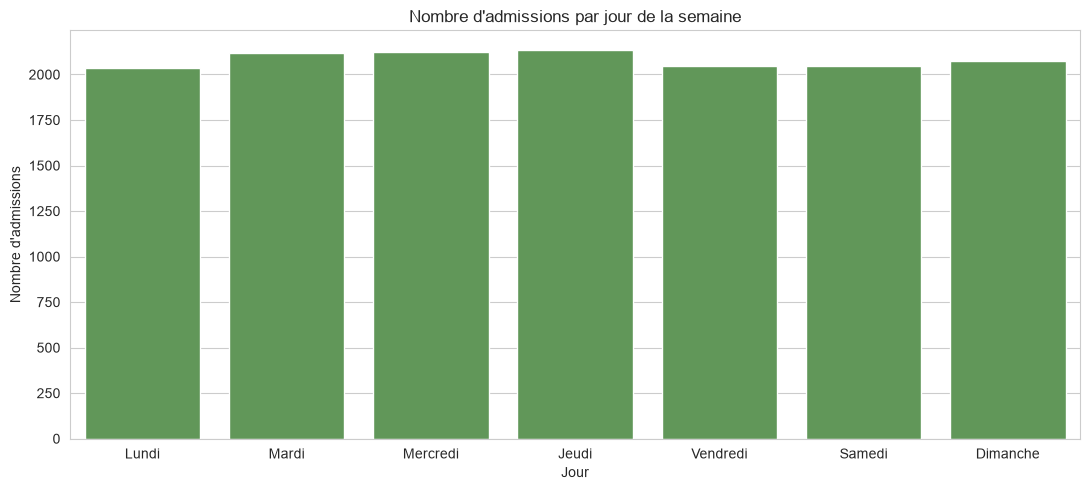

In [6]:
# --- Admissions par jour de la semaine ---
ordre_jours = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]
volumes_jour_semaine = df["jour_semaine"].value_counts().reindex(ordre_jours)

plt.figure()
sns.barplot(x=volumes_jour_semaine.index, y=volumes_jour_semaine.values, color="#59A14F")
plt.title("Nombre d'admissions par jour de la semaine")
plt.xlabel("Jour")
plt.ylabel("Nombre d'admissions")
plt.tight_layout()
plt.show()

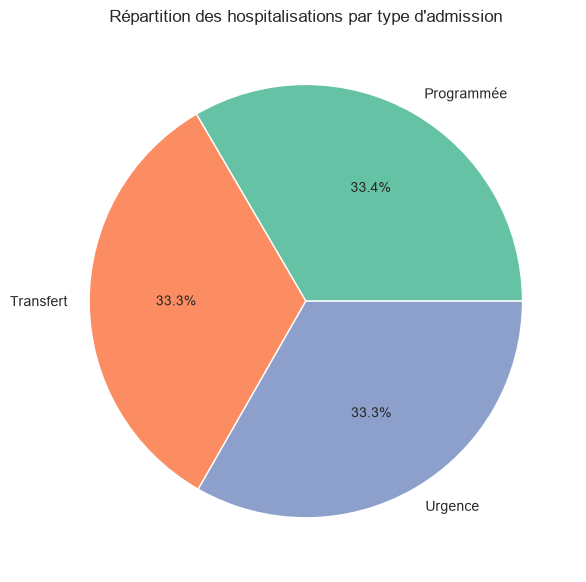

In [7]:
# --- Répartition par type d'admission ---
type_admission_counts = df["type_admission"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(type_admission_counts.values, labels=type_admission_counts.index, autopct="%1.1f%%",
        colors=sns.color_palette("Set2"))
plt.title("Répartition des hospitalisations par type d'admission")
plt.tight_layout()
plt.show()

## 4. Démographie des patients

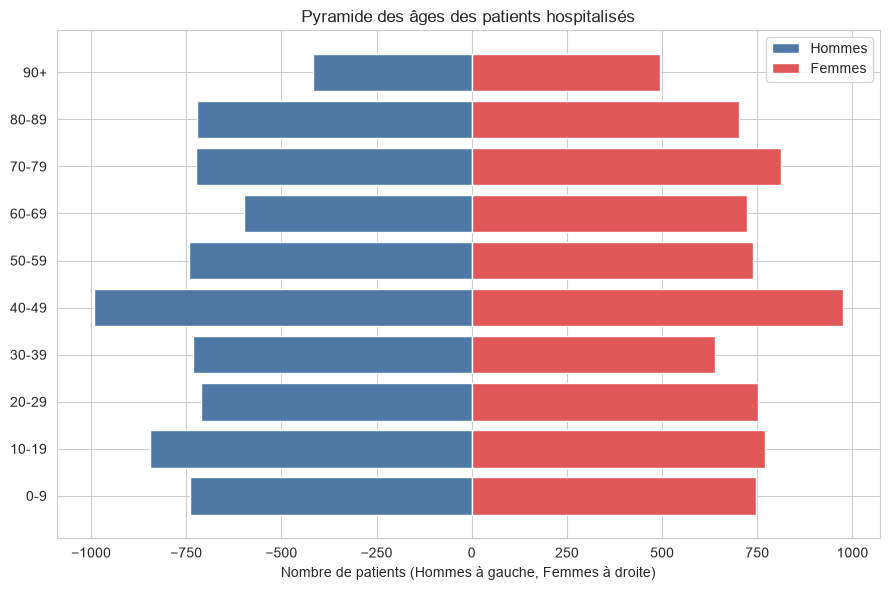

In [8]:
# --- Pyramide des âges ---
bins = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 120]
labels_bins = ["0-9", "10-19", "20-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80-89", "90+"]

df["groupe_age_fin"] = pd.cut(df["age"], bins=bins, labels=labels_bins, right=False)

pyramide = df.groupby(["groupe_age_fin", "sexe"], observed=True).size().unstack(fill_value=0)
pyramide["M"] = -pyramide.get("M", 0)  # négatif pour affichage en pyramide

plt.figure(figsize=(9, 6))
plt.barh(pyramide.index, pyramide["M"], color="#4E79A7", label="Hommes")
plt.barh(pyramide.index, pyramide.get("F", 0), color="#E15759", label="Femmes")
plt.title("Pyramide des âges des patients hospitalisés")
plt.xlabel("Nombre de patients (Hommes à gauche, Femmes à droite)")
plt.legend()
plt.tight_layout()
plt.show()

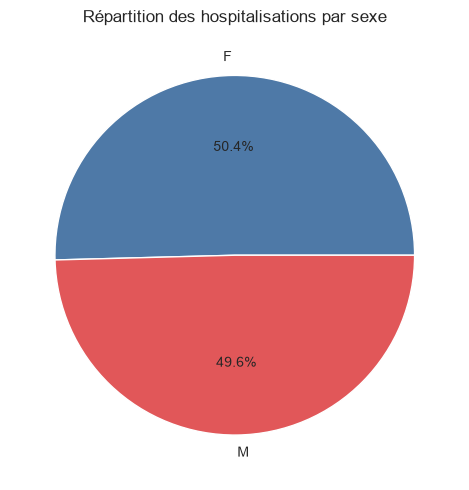

In [9]:
# --- Répartition par sexe ---
sexe_counts = df["sexe"].value_counts()

plt.figure(figsize=(5, 5))
plt.pie(sexe_counts.values, labels=sexe_counts.index, autopct="%1.1f%%", colors=["#4E79A7", "#E15759"])
plt.title("Répartition des hospitalisations par sexe")
plt.tight_layout()
plt.show()

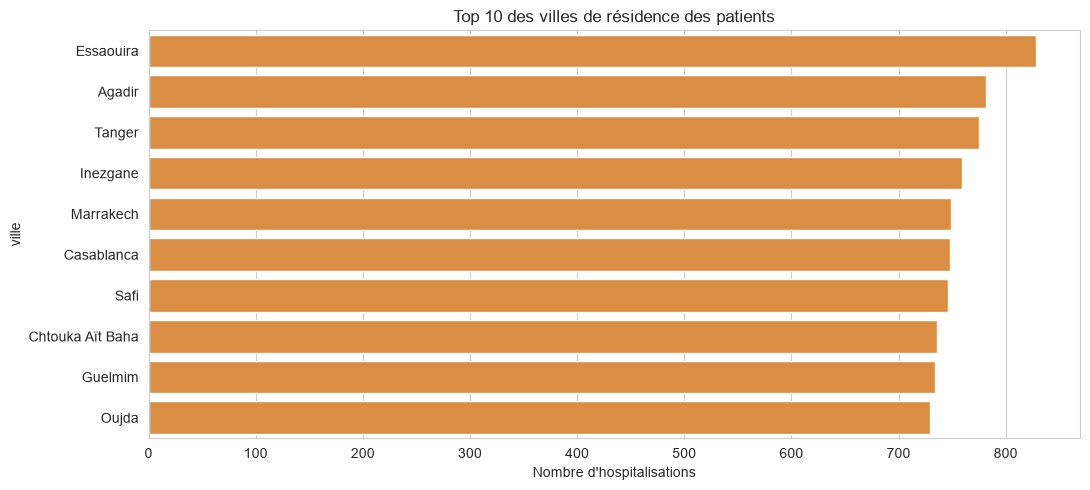

In [10]:
# --- Top 10 villes ---
top_villes = df["ville"].value_counts().head(10)

plt.figure()
sns.barplot(x=top_villes.values, y=top_villes.index, color="#F28E2B")
plt.title("Top 10 des villes de résidence des patients")
plt.xlabel("Nombre d'hospitalisations")
plt.tight_layout()
plt.show()

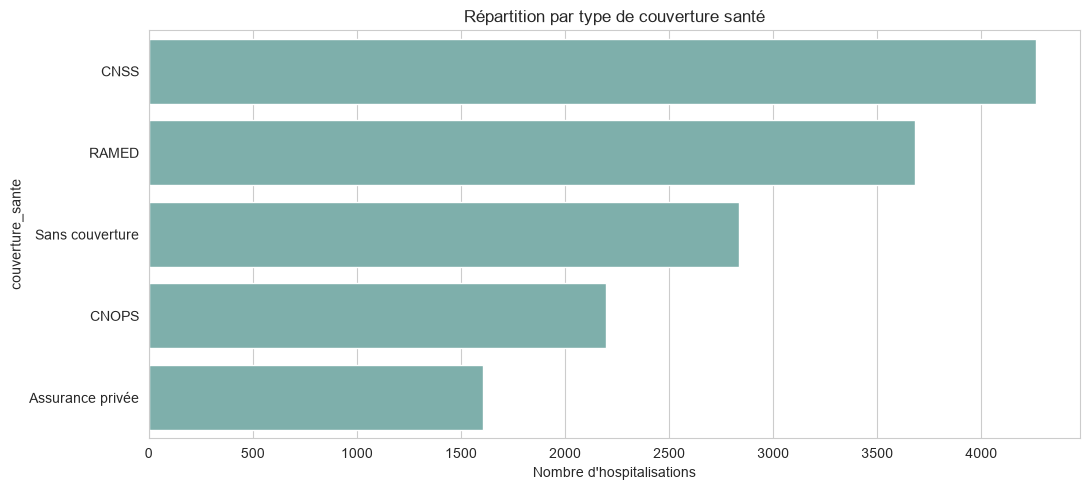

In [11]:
# --- Couverture santé ---
couverture_counts = df["couverture_sante"].value_counts()

plt.figure()
sns.barplot(x=couverture_counts.values, y=couverture_counts.index, color="#76B7B2")
plt.title("Répartition par type de couverture santé")
plt.xlabel("Nombre d'hospitalisations")
plt.tight_layout()
plt.show()

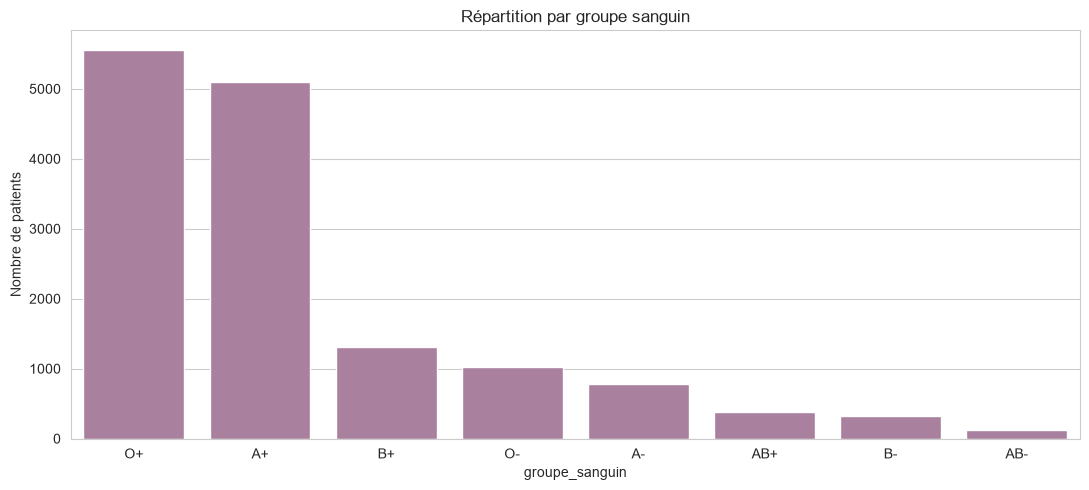

In [12]:
# --- Groupe sanguin ---
groupe_sanguin_counts = df["groupe_sanguin"].value_counts()

plt.figure()
sns.barplot(x=groupe_sanguin_counts.index, y=groupe_sanguin_counts.values, color="#B07AA1")
plt.title("Répartition par groupe sanguin")
plt.ylabel("Nombre de patients")
plt.tight_layout()
plt.show()

## 5. Analyse par service

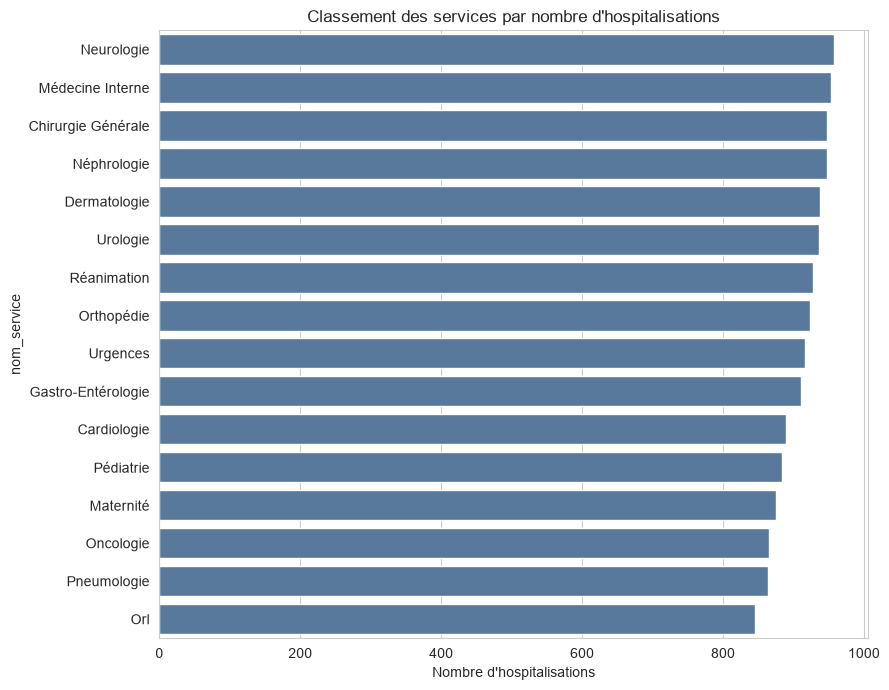

In [13]:
# --- Classement des services par volume d'activité ---
activite_services = df["nom_service"].value_counts()

plt.figure(figsize=(9, 7))
sns.barplot(x=activite_services.values, y=activite_services.index, color="#4E79A7")
plt.title("Classement des services par nombre d'hospitalisations")
plt.xlabel("Nombre d'hospitalisations")
plt.tight_layout()
plt.show()

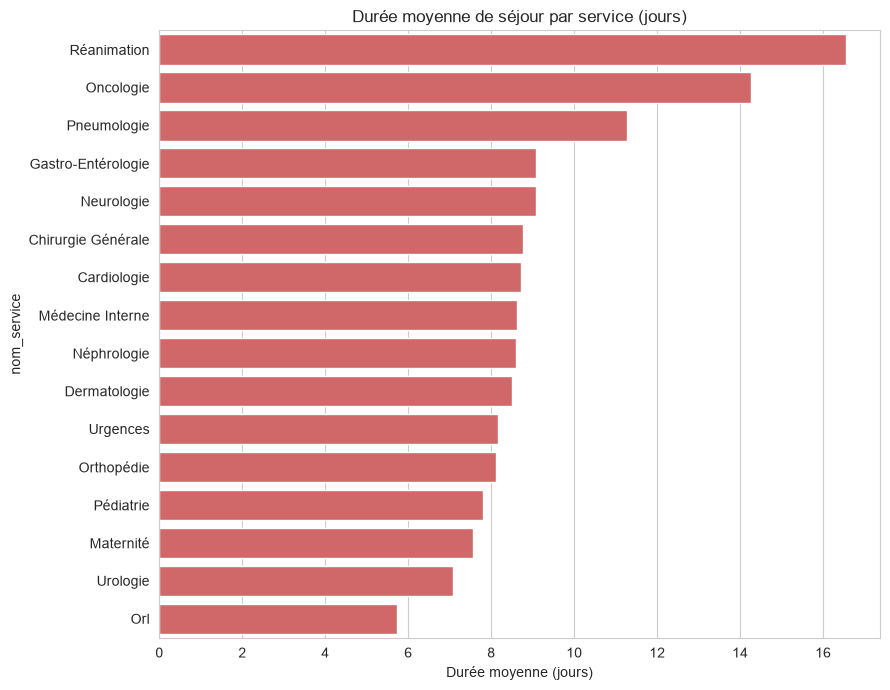

In [14]:
# --- Durée moyenne de séjour par service ---
duree_par_service = df.groupby("nom_service")["duree_sejour"].mean().sort_values(ascending=False)

plt.figure(figsize=(9, 7))
sns.barplot(x=duree_par_service.values, y=duree_par_service.index, color="#E15759")
plt.title("Durée moyenne de séjour par service (jours)")
plt.xlabel("Durée moyenne (jours)")
plt.tight_layout()
plt.show()

Période de référence : 1095 jours (du 2023-07-22 au 2026-07-21)


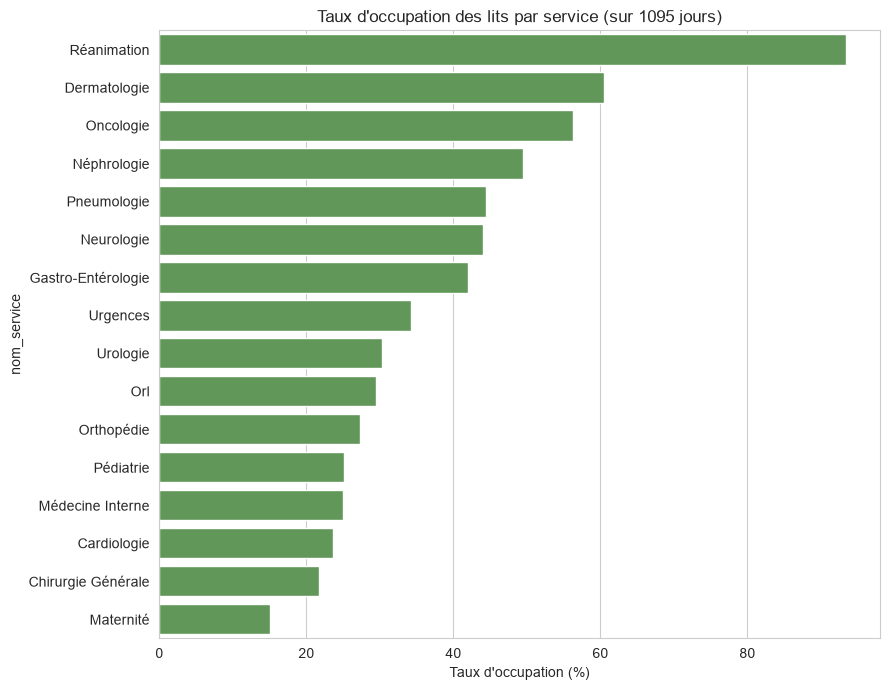

,nom_service,capacite_lits,jours_occupation_total,taux_occupation_pct
13,Réanimation,15,15336,93.37
14,Dermatologie,12,7955,60.54
5,Oncologie,20,12329,56.30
6,Néphrologie,15,8136,49.53
9,Pneumologie,20,9738,44.47
12,Neurologie,18,8686,44.07
10,Gastro-Entérologie,18,8272,41.97
3,Urgences,20,7483,34.17
11,Urologie,20,6629,30.27
15,Orl,15,4838,29.46


In [15]:
# --- Taux d'occupation des lits par service (sur toute la période du dataset) ---
df["date_entree"] = pd.to_datetime(df["date_entree"])  # sécurise le type, quelle que soit la source

jours_periode_total = (df["date_entree"].max() - df["date_entree"].min()).days
print(f"Période de référence : {jours_periode_total} jours (du {df['date_entree'].min().date()} au {df['date_entree'].max().date()})")

occupation_service = df.groupby(["id_service", "nom_service"]).agg(
    jours_occupation_total=("jours_occupation", "sum"),
    capacite_lits=("capacite_lits", "first"),
).reset_index()

occupation_service["taux_occupation_pct"] = (
    occupation_service["jours_occupation_total"]
    / (occupation_service["capacite_lits"] * jours_periode_total)
    * 100
).round(2)

occupation_service = occupation_service.sort_values("taux_occupation_pct", ascending=False)

plt.figure(figsize=(9, 7))
sns.barplot(data=occupation_service, x="taux_occupation_pct", y="nom_service", color="#59A14F")
plt.title(f"Taux d'occupation des lits par service (sur {jours_periode_total} jours)")
plt.xlabel("Taux d'occupation (%)")
plt.tight_layout()
plt.show()

occupation_service[["nom_service", "capacite_lits", "jours_occupation_total", "taux_occupation_pct"]]

## 6. Analyse des durées de séjour

In [16]:
# --- Statistiques globales ---
print(df["duree_sejour"].describe())

count    14580.000000
mean         9.237449
std          4.089991
min          2.000000
25%          6.000000
50%          9.000000
75%         12.000000
max         29.000000
Name: duree_sejour, dtype: float64


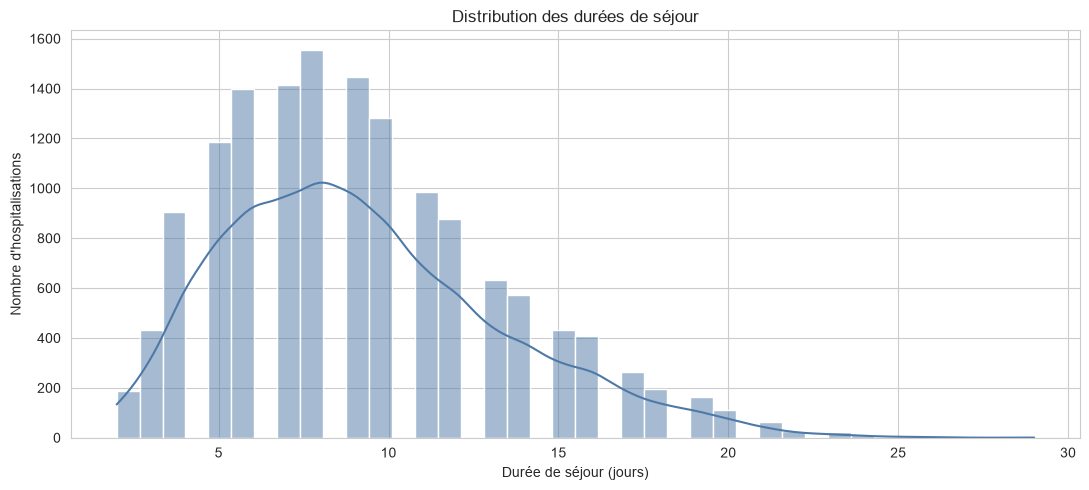

In [17]:
# --- Distribution globale (histogramme) ---
plt.figure()
sns.histplot(df["duree_sejour"], bins=40, color="#4E79A7", kde=True)
plt.title("Distribution des durées de séjour")
plt.xlabel("Durée de séjour (jours)")
plt.ylabel("Nombre d'hospitalisations")
plt.tight_layout()
plt.show()

C:\Users\0oo-u\AppData\Local\Temp\ipykernel_14536\432644758.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="nom_service", y="duree_sejour", order=ordre_services, palette="Set3")


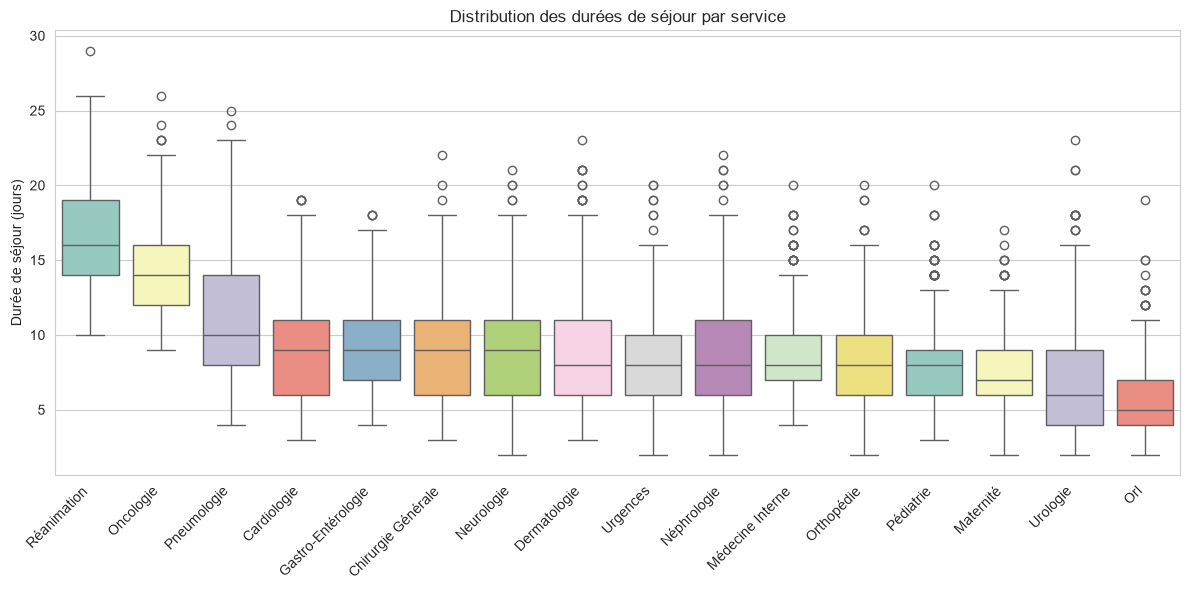

In [18]:
# --- Durée de séjour par service (boxplot) ---
plt.figure(figsize=(12, 6))
ordre_services = df.groupby("nom_service")["duree_sejour"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="nom_service", y="duree_sejour", order=ordre_services, palette="Set3")
plt.xticks(rotation=45, ha="right")
plt.title("Distribution des durées de séjour par service")
plt.ylabel("Durée de séjour (jours)")
plt.xlabel("")
plt.tight_layout()
plt.show()

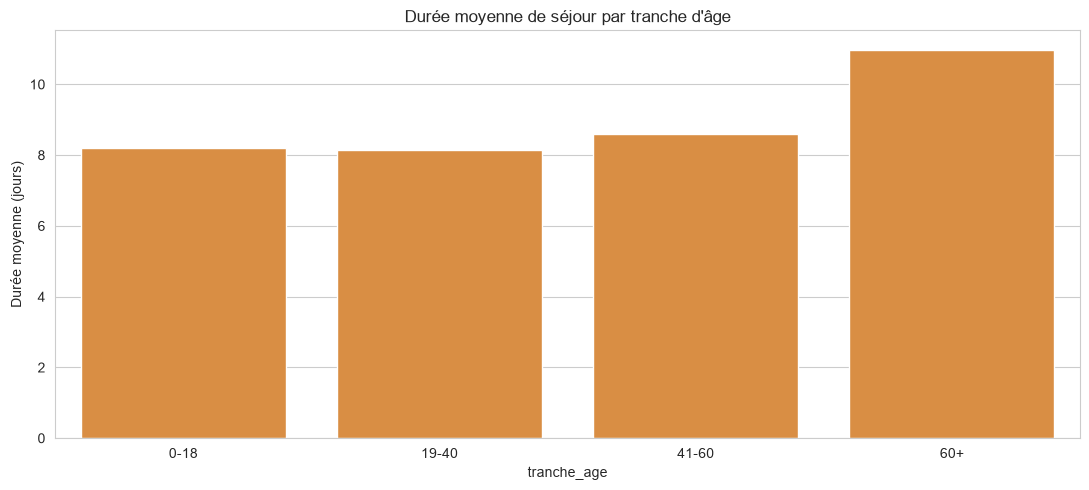

In [19]:
# --- Durée moyenne par tranche d'âge ---
duree_par_tranche_age = df.groupby("tranche_age", observed=True)["duree_sejour"].mean().reindex(["0-18", "19-40", "41-60", "60+"])

plt.figure()
sns.barplot(x=duree_par_tranche_age.index, y=duree_par_tranche_age.values, color="#F28E2B")
plt.title("Durée moyenne de séjour par tranche d'âge")
plt.ylabel("Durée moyenne (jours)")
plt.tight_layout()
plt.show()

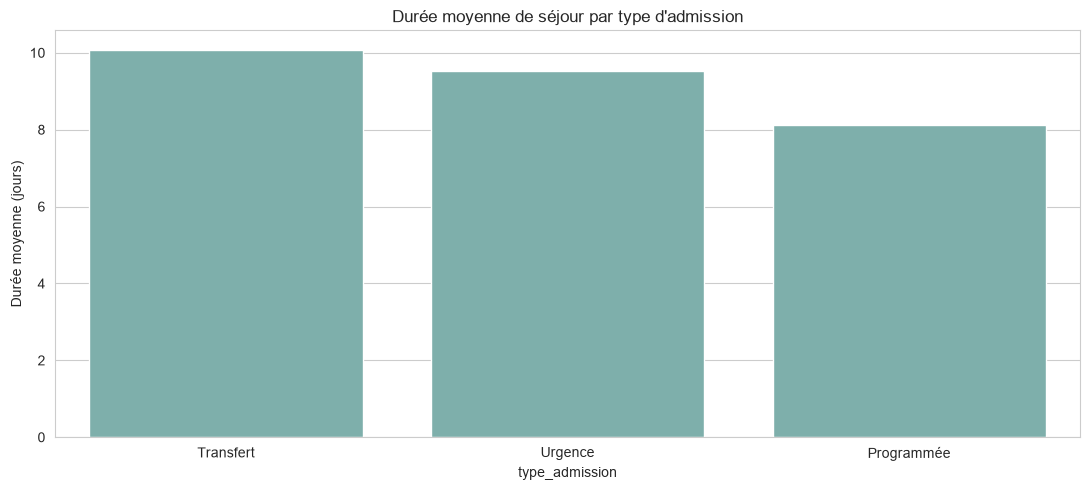

In [20]:
# --- Durée moyenne par type d'admission ---
duree_par_type_admission = df.groupby("type_admission")["duree_sejour"].mean().sort_values(ascending=False)

plt.figure()
sns.barplot(x=duree_par_type_admission.index, y=duree_par_type_admission.values, color="#76B7B2")
plt.title("Durée moyenne de séjour par type d'admission")
plt.ylabel("Durée moyenne (jours)")
plt.tight_layout()
plt.show()

## 7. Analyse des pathologies

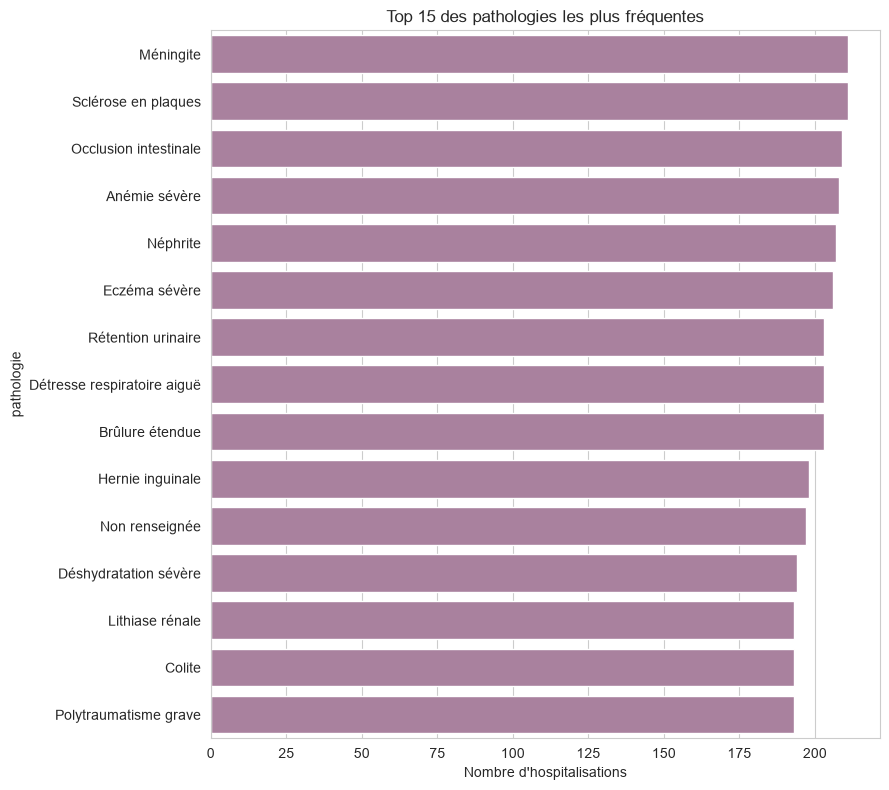

In [21]:
# --- Top 15 pathologies globales ---
top_pathologies = df["pathologie"].value_counts().head(15)

plt.figure(figsize=(9, 8))
sns.barplot(x=top_pathologies.values, y=top_pathologies.index, color="#B07AA1")
plt.title("Top 15 des pathologies les plus fréquentes")
plt.xlabel("Nombre d'hospitalisations")
plt.tight_layout()
plt.show()

In [22]:
# --- Pathologie la plus fréquente par service ---
pathologie_dominante_par_service = (
    df.groupby("nom_service")["pathologie"]
    .agg(lambda x: x.value_counts().idxmax())
    .reset_index(name="pathologie_dominante")
)
pathologie_dominante_par_service

,nom_service,pathologie_dominante
0,Cardiologie,Angine de poitrine
1,Chirurgie Générale,Occlusion intestinale
2,Dermatologie,Eczéma sévère
3,Gastro-Entérologie,Colite
4,Maternité,Pré-éclampsie
5,Médecine Interne,Anémie sévère
6,Neurologie,Méningite
7,Néphrologie,Néphrite
8,Oncologie,Cancer du poumon
9,Orl,Amygdalite


## 8. Charge de travail par médecin

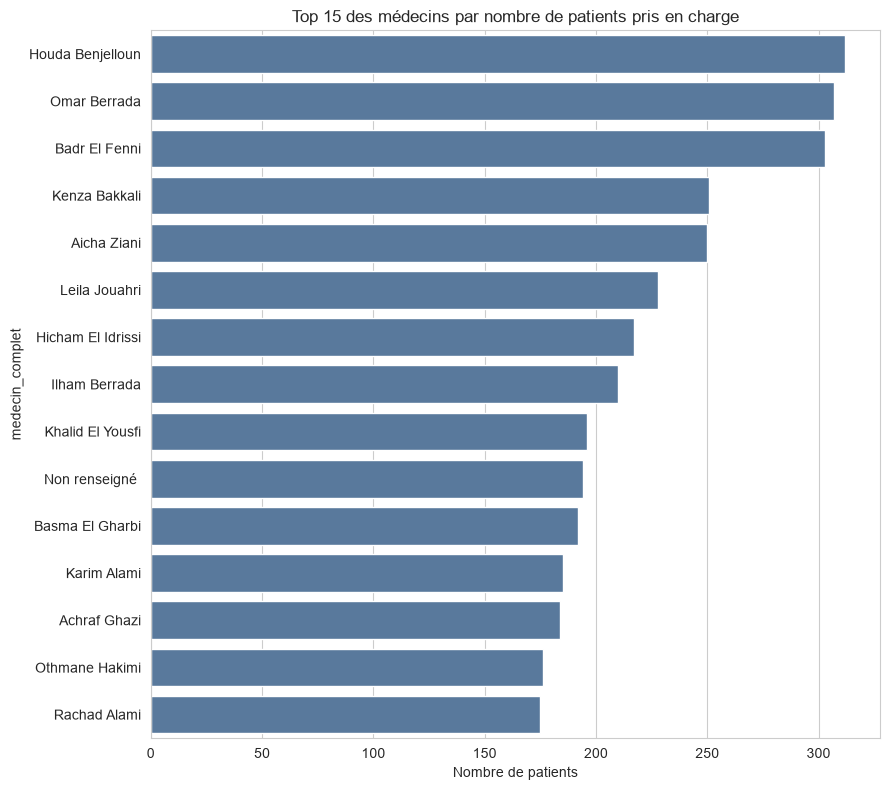

In [23]:
# --- Top 15 médecins par nombre de patients pris en charge ---
df["medecin_complet"] = df["prenom_medecin"].fillna("Non renseigné") + " " + df["nom_medecin"].fillna("")
charge_medecins = df["medecin_complet"].value_counts().head(15)

plt.figure(figsize=(9, 8))
sns.barplot(x=charge_medecins.values, y=charge_medecins.index, color="#4E79A7")
plt.title("Top 15 des médecins par nombre de patients pris en charge")
plt.xlabel("Nombre de patients")
plt.tight_layout()
plt.show()

Top 1 médecin par service :


,nom_service,medecin_complet,nb_patients_pris_en_charge
2,Dermatologie,Houda Benjelloun,312
14,Urgences,Aicha Ziani,250
3,Gastro-Entérologie,Khalid El Yousfi,196
12,Pédiatrie,Karim Alami,185
11,Pneumologie,Yousra Kettani,173
6,Neurologie,Yousra Habibi,166
4,Maternité,Mehdi Benjelloun,154
7,Néphrologie,Yassine Amrani,148
15,Urologie,Aziz Chraibi,143
13,Réanimation,Yassir Naciri,141



Top 3 médecins par service :


,nom_service,medecin_complet,nb_patients_pris_en_charge
0,Cardiologie,Sanae El Fenni,124
1,Cardiologie,Mounir Cherkaoui,117
2,Cardiologie,Othmane Dahbi,113
3,Chirurgie Générale,Kamal El Amrani,139
4,Chirurgie Générale,Basma Bakkali,138
5,Chirurgie Générale,Elhassane El Yousfi,138
6,Dermatologie,Houda Benjelloun,312
7,Dermatologie,Omar Berrada,307
8,Dermatologie,Badr El Fenni,303
9,Gastro-Entérologie,Khalid El Yousfi,196


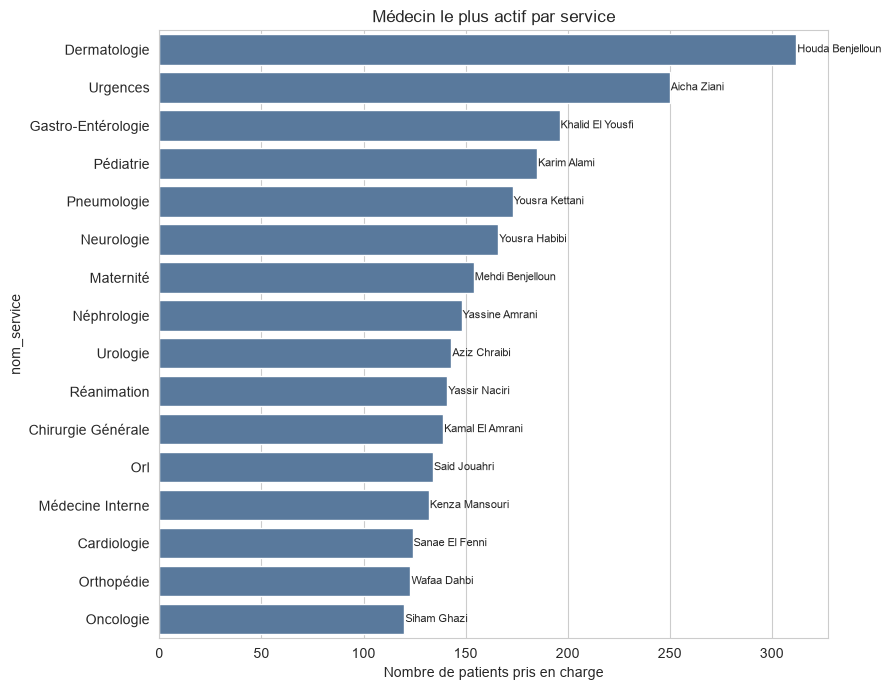

In [24]:
# --- Top médecin(s) par service ---
df["medecin_complet"] = df["prenom_medecin"].fillna("Non renseigné") + " " + df["nom_medecin"].fillna("")

charge_par_medecin_service = (
    df.groupby(["nom_service", "medecin_complet"])
    .size()
    .reset_index(name="nb_patients_pris_en_charge")
)

# --- Top 1 médecin par service ---
top1_medecin_par_service = (
    charge_par_medecin_service
    .sort_values("nb_patients_pris_en_charge", ascending=False)
    .groupby("nom_service")
    .first()
    .reset_index()
    .sort_values("nb_patients_pris_en_charge", ascending=False)
)

print("Top 1 médecin par service :")
display(top1_medecin_par_service)

# --- Top 3 médecins par service (plus de contexte) ---
top3_medecins_par_service = (
    charge_par_medecin_service
    .sort_values(["nom_service", "nb_patients_pris_en_charge"], ascending=[True, False])
    .groupby("nom_service")
    .head(3)
    .reset_index(drop=True)
)

print("\nTop 3 médecins par service :")
display(top3_medecins_par_service)

# --- Visualisation : top 1 médecin par service ---
plt.figure(figsize=(9, 7))
sns.barplot(
    data=top1_medecin_par_service,
    x="nb_patients_pris_en_charge",
    y="nom_service",
    color="#4E79A7"
)
for i, row in enumerate(top1_medecin_par_service.itertuples()):
    plt.text(row.nb_patients_pris_en_charge + 0.5, i, row.medecin_complet, va="center", fontsize=8)
plt.title("Médecin le plus actif par service")
plt.xlabel("Nombre de patients pris en charge")
plt.tight_layout()
plt.show()

## 9. Analyse du mode de sortie

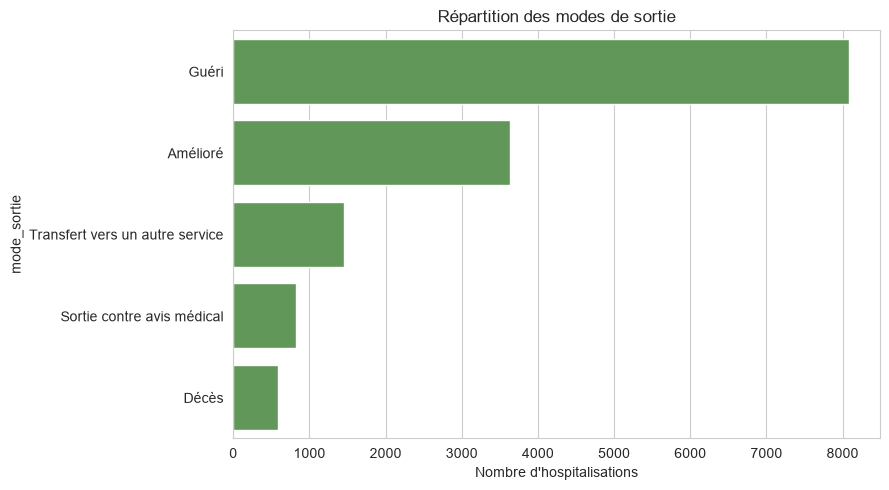

mode_sortie
Guéri                              55.47
Amélioré                           24.91
Transfert vers un autre service     9.96
Sortie contre avis médical          5.66
Décès                               4.01
Name: count, dtype: float64

In [25]:
# --- Répartition globale des modes de sortie ---
mode_sortie_counts = df["mode_sortie"].value_counts()

plt.figure(figsize=(9, 5))
sns.barplot(x=mode_sortie_counts.values, y=mode_sortie_counts.index, color="#59A14F")
plt.title("Répartition des modes de sortie")
plt.xlabel("Nombre d'hospitalisations")
plt.tight_layout()
plt.show()

mode_sortie_pct = (mode_sortie_counts / len(df) * 100).round(2)
mode_sortie_pct

In [26]:
# --- Taux par mode de sortie, par service (tableau croisé) ---
tableau_mode_sortie_service = pd.crosstab(df["nom_service"], df["mode_sortie"], normalize="index").round(3) * 100
tableau_mode_sortie_service

mode_sortie,Amélioré,Décès,Guéri,Sortie contre avis médical,Transfert vers un autre service
nom_service,,,,,
Cardiologie,25.1,4.0,55.8,5.5,9.6
Chirurgie Générale,23.8,3.8,55.8,4.5,12.0
Dermatologie,24.0,3.7,56.8,5.1,10.4
Gastro-Entérologie,23.4,4.5,56.8,5.2,10.2
Maternité,25.9,3.7,56.0,5.7,8.7
Médecine Interne,27.6,4.1,53.4,4.4,10.5
Neurologie,23.9,4.1,55.7,6.2,10.1
Néphrologie,24.6,4.1,58.3,4.8,8.2
Oncologie,20.7,4.6,55.7,6.9,12.0


## 10. Corrélations entre variables numériques

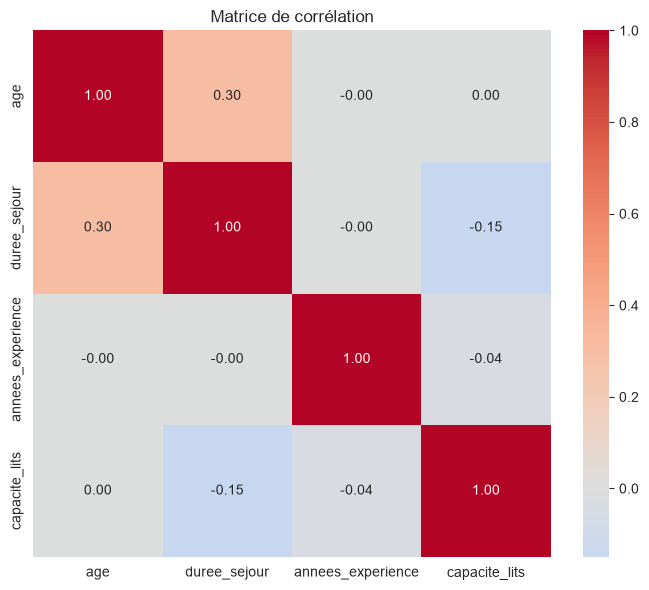

In [27]:
colonnes_numeriques = ["age", "duree_sejour", "annees_experience", "capacite_lits"]
matrice_correlation = df[colonnes_numeriques].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(matrice_correlation, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()

## 11. Tableau des KPI consolidés

Vue d'ensemble unique, directement réutilisable pour la page "Exécutive" de Power BI.

In [28]:
kpi_globaux = {
    "Total hospitalisations": len(df),
    "Nombre de patients uniques": df["id_patient"].nunique(),
    "Durée moyenne de séjour (jours)": round(df["duree_sejour"].mean(), 2),
    "Durée médiane de séjour (jours)": df["duree_sejour"].median(),
    "Durée min de séjour (jours)": df["duree_sejour"].min(),
    "Durée max de séjour (jours)": df["duree_sejour"].max(),
    "Taux d'occupation global des lits (%)": round(
        occupation_service["jours_occupation_total"].sum()
        / (occupation_service["capacite_lits"].sum() * jours_periode_total) * 100, 2
    ),
    "Nombre de services": df["nom_service"].nunique(),
    "Nombre de médecins actifs": df["id_medecin"].nunique(),
    "Taux d'admissions en urgence (%)": round((df["type_admission"] == "Urgence").mean() * 100, 2),
    "Taux de guérison (%)": round((df["mode_sortie"] == "Guéri").mean() * 100, 2),
    "Taux de décès (%)": round((df["mode_sortie"] == "Décès").mean() * 100, 2),
    "Âge moyen des patients": round(df["age"].mean(), 1),
    "Pourcentage de patients de sexe féminin (%)": round((df["sexe"] == "F").mean() * 100, 2),
}

df_kpi_globaux = pd.DataFrame(list(kpi_globaux.items()), columns=["indicateur", "valeur"])
df_kpi_globaux

,indicateur,valeur
0,Total hospitalisations,14580.00
1,Nombre de patients uniques,6666.00
2,Durée moyenne de séjour (jours),9.24
3,Durée médiane de séjour (jours),9.00
4,Durée min de séjour (jours),2.00
5,Durée max de séjour (jours),29.00
6,Taux d'occupation global des lits (%),34.36
7,Nombre de services,16.00
8,Nombre de médecins actifs,103.00
9,Taux d'admissions en urgence (%),33.27


In [29]:
# --- KPI détaillés par service (table prête pour Power BI) ---
kpi_par_service = df.groupby("nom_service").agg(
    nb_hospitalisations=("id_fait", "count"),
    duree_moyenne_sejour=("duree_sejour", "mean"),
    duree_mediane_sejour=("duree_sejour", "median"),
    age_moyen_patients=("age", "mean"),
    taux_urgence_pct=("type_admission", lambda x: (x == "Urgence").mean() * 100),
    taux_deces_pct=("mode_sortie", lambda x: (x == "Décès").mean() * 100),
).round(2).reset_index()

kpi_par_service = kpi_par_service.merge(
    occupation_service[["nom_service", "capacite_lits", "taux_occupation_pct"]], on="nom_service"
)

kpi_par_service = kpi_par_service.sort_values("nb_hospitalisations", ascending=False)
kpi_par_service

,nom_service,nb_hospitalisations,duree_moyenne_sejour,duree_mediane_sejour,age_moyen_patients,taux_urgence_pct,taux_deces_pct,capacite_lits,taux_occupation_pct
6,Neurologie,958,9.07,9.0,47.00,32.36,4.07,18,44.07
5,Médecine Interne,953,8.63,8.0,46.94,33.47,4.09,30,25.04
1,Chirurgie Générale,948,8.77,9.0,46.79,34.60,3.80,35,21.70
7,Néphrologie,947,8.59,8.0,47.38,35.27,4.12,15,49.53
2,Dermatologie,937,8.49,8.0,46.37,34.58,3.74,12,60.54
15,Urologie,936,7.08,6.0,47.08,32.48,3.74,20,30.27
13,Réanimation,927,16.54,16.0,46.85,32.25,4.10,15,93.37
10,Orthopédie,923,8.11,8.0,47.69,32.50,3.14,25,27.34
14,Urgences,917,8.16,8.0,48.94,32.50,4.03,20,34.17
3,Gastro-Entérologie,911,9.08,9.0,46.01,33.04,4.50,18,41.97


## 12. Export des résultats

In [30]:
with pd.ExcelWriter(f"{EXPORT_DIR}/kpi_consolides.xlsx", engine="openpyxl") as writer:
    df_kpi_globaux.to_excel(writer, sheet_name="KPI_globaux", index=False)
    kpi_par_service.to_excel(writer, sheet_name="KPI_par_service", index=False)
    volumes_mensuels.to_excel(writer, sheet_name="Volumes_mensuels", index=False)
    tableau_mode_sortie_service.to_excel(writer, sheet_name="Mode_sortie_par_service")

# Export CSV individuels également (pour usage direct dans Power BI si préféré)
df_kpi_globaux.to_csv(f"{EXPORT_DIR}/kpi_globaux.csv", index=False)
kpi_par_service.to_csv(f"{EXPORT_DIR}/kpi_par_service.csv", index=False)
volumes_mensuels.to_csv(f"{EXPORT_DIR}/volumes_mensuels.csv", index=False)

print("Exports terminés dans data/exports/ ")
print("- kpi_consolides.xlsx (4 onglets)")
print("- kpi_globaux.csv")
print("- kpi_par_service.csv")
print("- volumes_mensuels.csv")

Exports terminés dans data/exports/ 
- kpi_consolides.xlsx (4 onglets)
- kpi_globaux.csv
- kpi_par_service.csv
- volumes_mensuels.csv


---
### Récapitulatif des analyses couvertes dans ce notebook

- **Volumes** : tendance mensuelle, par année, par jour de semaine, par type d'admission
- **Démographie** : pyramide des âges, sexe, top villes, couverture santé, groupe sanguin
- **Services** : classement d'activité, durée moyenne, **taux d'occupation des lits** (sur toute la période 2023-2026)
- **Séjours** : distribution globale, boxplot par service, durée par tranche d'âge et par type d'admission
- **Pathologies** : top 15 global, pathologie dominante par service
- **Médecins** : charge de travail (top 15)
- **Mode de sortie** : répartition globale + tableau croisé par service
- **Corrélations** : matrice de corrélation des variables numériques
- **KPI consolidés** : tableau global + tableau détaillé par service, exportés en Excel (4 onglets) et CSV

### Prochaine étape
Ouvrir `05_modele_prediction_duree_sejour.ipynb` pour construire le modèle de Machine Learning (Semaine 6).